# ARC-AGI-2 — LLM pipeline analysis

A small language model (Qwen3-0.6B, later Qwen3-1.7B) reads each task as text and writes the test output grid.
Every test input is shown under 8 views (the original plus 7 random rotations/reflections,
colour permutations and example orders); answers are mapped back to the original orientation and
the two most-voted grids become attempts 1 and 2.

| Run | Model |
|---|---|
| `zero-shot` | Qwen3-0.6B as released |
| `fine-tuned` | + LoRA adapter trained on the training split (real tasks, leave-one-out, augmented) and synthetic DSL tasks |
| `test-time trained` | + one more epoch on the evaluation tasks' own demonstration pairs (leave-one-out, 16 augmentations each, 15% generic rows mixed in); their test outputs are never used |
| `per-task TTT` | fine-tuned adapter + a separate adapter per task, trained only on that task's demonstrations (leave-one-out, 16 augmentations, 2 epochs) |
| `per-task TTT, rescored` | the same answers, with the top 8 candidates per test re-ranked by summed log-probability across the 8 views (findings table only) |
| `1.7B fine-tuned` | Qwen3-1.7B + LoRA trained on the training split plus 10,000 RE-ARC pseudo-tasks (generated examples of the 400 original ARC training tasks) |
| `1.7B per-task TTT` | the 1.7B adapter + a separate adapter per task (as `per-task TTT`), rescored |
| `1.7B sampled` | as `1.7B per-task TTT`, plus 4 sampled answers per view (temperature 0.7); the top 12 candidates are rescored |

Section 8 compares ways of ranking the sampled candidates, and section 9 tries a different generator:
a 20B reasoning model that writes Python programs, checked against the demonstrations.

Unless marked otherwise, scores are on the 120-task public **evaluation** split. No model saw its test outputs; only the
test-time-trained adapter saw its demonstration pairs, which every solver is given anyway.

## 1. Setup

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from solver.grid import load_split
from taskstats import category

RES = Path("results")
# Evaluation runs to compare, in order (add test-time-training runs here later)
# (shared TTT, the rescored-only 0.6B run and per-task v2 are in the findings table; six runs keep the plots readable)
RUNS = {"zero-shot": "llm_evaluation_zeroshot_q06", "fine-tuned": "llm_evaluation_lora_q06",
        "per-task TTT": "llm_evaluation_ttt_task_q06",
        "1.7B fine-tuned": "llm_evaluation_lora_q17", "1.7B per-task TTT": "llm_evaluation_ttt_task_q17",
        "1.7B sampled": "llm_evaluation_ttt_task_sample_q17"}
TRAIN_LOGS = {"0.6B fine-tuning": RES / "llm_train_q06.log", "1.7B fine-tuning (+RE-ARC)": RES / "llm_train_q17.log"}

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#7d5bd6"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "lines.linewidth": 2,
})
ARC_CMAP = ListedColormap(["#000000", "#0074D9", "#FF4136", "#2ECC40", "#FFDC00",
                           "#AAAAAA", "#F012BE", "#FF851B", "#7FDBFF", "#870C25"])

eval_tasks = load_split("evaluation")
cat_eval = pd.Series({t: category(v) for t, v in eval_tasks.items()})
runs = {name: json.loads((RES / f"{f}.json").read_text()) for name, f in RUNS.items() if (RES / f"{f}.json").exists()}
COLOR = dict(zip(runs, SERIES))


def tests_frame(run):
    """One row per test input, with task-level descriptors attached."""
    rows = []
    for t in run["tasks"]:
        for i, d in enumerate(t.get("tests", [])):
            y = eval_tasks[t["task"]]["test"][i][1]
            rows.append({"task": t["task"], "test": i, **{k: v for k, v in d.items() if k != "attempts"},
                         "top_votes": d["votes"][0] if d["votes"] else 0,
                         "out_cells": y.size, "category": cat_eval[t["task"]]})
    return pd.DataFrame(rows)


frames = {name: tests_frame(r) for name, r in runs.items()}
print("runs loaded:", {n: f"{len(f)} test inputs" for n, f in frames.items()})

runs loaded: {'zero-shot': '167 test inputs', 'fine-tuned': '167 test inputs', 'per-task TTT': '167 test inputs', '1.7B fine-tuned': '167 test inputs', '1.7B per-task TTT': '167 test inputs', '1.7B sampled': '167 test inputs'}


## 2. Training curves

0.6B fine-tuning: validation loss 0.384 -> 0.139
1.7B fine-tuning (+RE-ARC): validation loss 0.375 -> 0.098


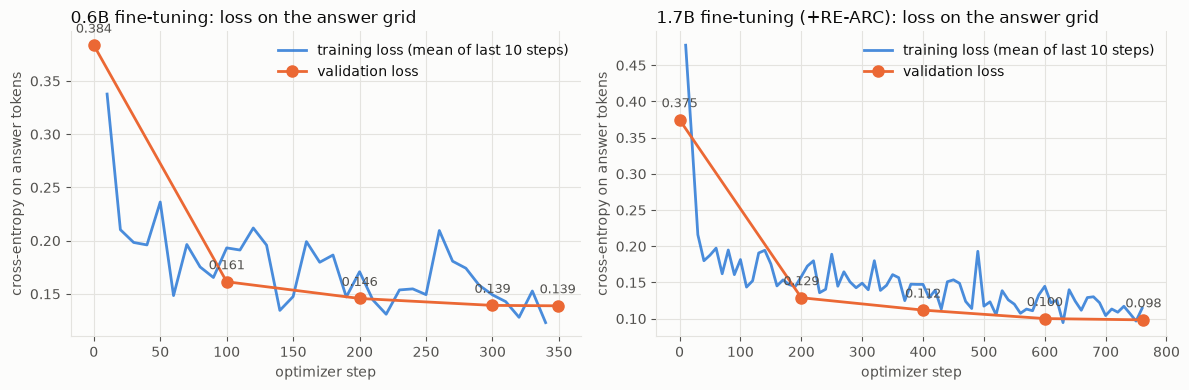

Test-time validation rows come from the same evaluation tasks as its training rows, so that curve is not a held-out signal.


In [2]:
def read_log(path):
    train_pts, val_pts = [], []
    for line in path.read_text().splitlines() if path.exists() else []:
        if m := re.match(r"step (\d+)/\d+ loss ([\d.]+)", line):
            train_pts.append((int(m[1]), float(m[2])))
        elif m := re.match(r"step (\d+) val_loss ([\d.]+)", line):
            val_pts.append((int(m[1]), float(m[2])))
    return train_pts, val_pts

logs = {name: read_log(path) for name, path in TRAIN_LOGS.items()}
fig, axes = plt.subplots(1, len(logs), figsize=(12, 4), squeeze=False)
for ax, (name, (train_pts, val_pts)) in zip(axes[0], logs.items()):
    if train_pts:
        s, l = zip(*train_pts)
        ax.plot(s, l, color=SERIES[0], alpha=0.85, label="training loss (mean of last 10 steps)")
    if val_pts:
        s, l = zip(*val_pts)
        ax.plot(s, l, color=SERIES[1], marker="o", markersize=8, label="validation loss")
        for x, y in val_pts:
            ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", color=INK2, fontsize=9)
    ax.set(xlabel="optimizer step", ylabel="cross-entropy on answer tokens")
    ax.set_title(f"{name}: loss on the answer grid", loc="left")
    ax.legend(frameon=False)
    if val_pts:
        print(f"{name}: validation loss {val_pts[0][1]:.3f} -> {val_pts[-1][1]:.3f}")
plt.tight_layout(); plt.show()
print("Test-time validation rows come from the same evaluation tasks as its training rows, "
      "so that curve is not a held-out signal.")

## 3. Before vs after

* **valid** — the model wrote a well-formed grid (rectangular, digits only)
* **right size** — the top-voted grid has the expected height and width
* **cell accuracy** — share of cells correct, on test inputs where the size is right
* **solved** — attempt 1 or 2 is exactly right (the ARC metric)

,solved (of 120),valid grids %,right size %,cell accuracy % (right size),minutes
zero-shot,0.0,56.8,31.7,79.1,9.8
fine-tuned,0.0,76.8,61.1,81.7,13.3
per-task TTT,0.5,80.2,59.9,82.3,14.5
1.7B fine-tuned,0.0,89.2,71.3,80.2,14.6
1.7B per-task TTT,0.0,88.6,73.7,83.9,46.5
1.7B sampled,0.0,88.5,73.7,83.4,102.6


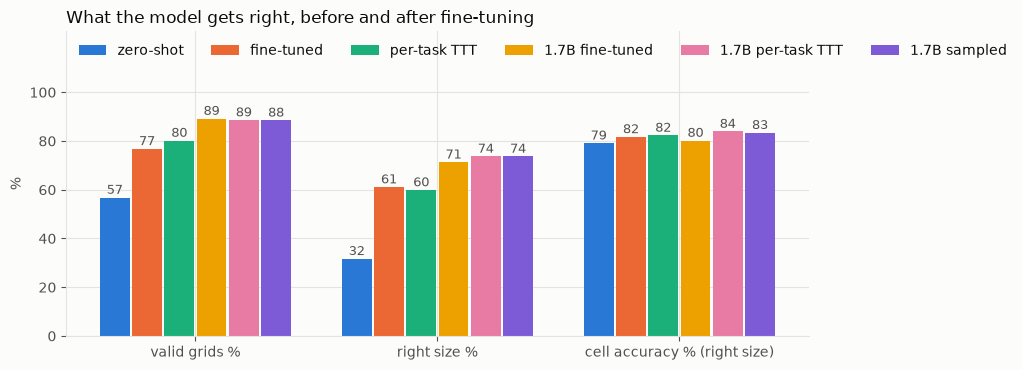

In [3]:
def headline(name):
    f, r = frames[name], runs[name]
    return {"solved (of 120)": r["score"], "valid grids %": 100 * f["valid"].sum() / f["views"].sum(),
            "right size %": 100 * f["shape_ok"].mean(),
            "cell accuracy % (right size)": 100 * f.loc[f["shape_ok"], "cell_acc"].mean() if f["shape_ok"].any() else 0,
            "minutes": r["seconds"] / 60}

head = pd.DataFrame({n: headline(n) for n in frames}).T.round(1)
display(head)

metrics = ["valid grids %", "right size %", "cell accuracy % (right size)"]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(metrics))
w = 0.8 / len(head)
for k, name in enumerate(head.index):
    vals = head.loc[name, metrics].to_numpy(float)
    bars = ax.bar(x + (k - (len(head) - 1) / 2) * w, vals, w * 0.92, color=COLOR[name], label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, metrics); ax.set_ylim(0, 125); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("%")
ax.set_title("What the model gets right, before and after fine-tuning", loc="left")
ax.legend(frameon=False, loc="upper left", ncol=len(head))
plt.tight_layout(); plt.show()

## 4. Near misses: how close are the wrong answers?

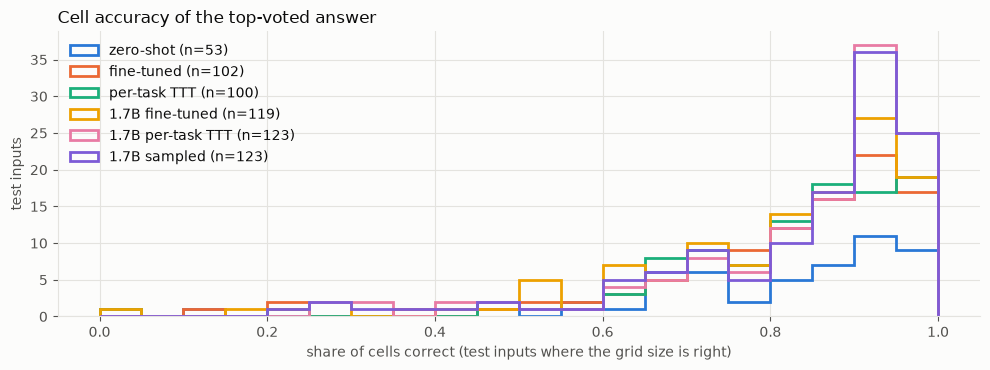

1.7B sampled: 61 test inputs with >=90% of cells right, 2 with >=99%, 0 exactly right


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.linspace(0, 1, 21)
for name, f in frames.items():
    acc = f.loc[f["shape_ok"], "cell_acc"]
    ax.hist(acc, bins=bins, histtype="step", linewidth=2, color=COLOR[name], label=f"{name} (n={len(acc)})")
ax.set(xlabel="share of cells correct (test inputs where the grid size is right)", ylabel="test inputs")
ax.set_title("Cell accuracy of the top-voted answer", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
last = list(frames)[-1]
f = frames[last]
print(f"{last}: {(f['cell_acc'] >= 0.9).sum()} test inputs with >=90% of cells right, "
      f"{(f['cell_acc'] >= 0.99).sum()} with >=99%, {int(f['correct'].sum())} exactly right")

## 5. Where does it do better or worse?

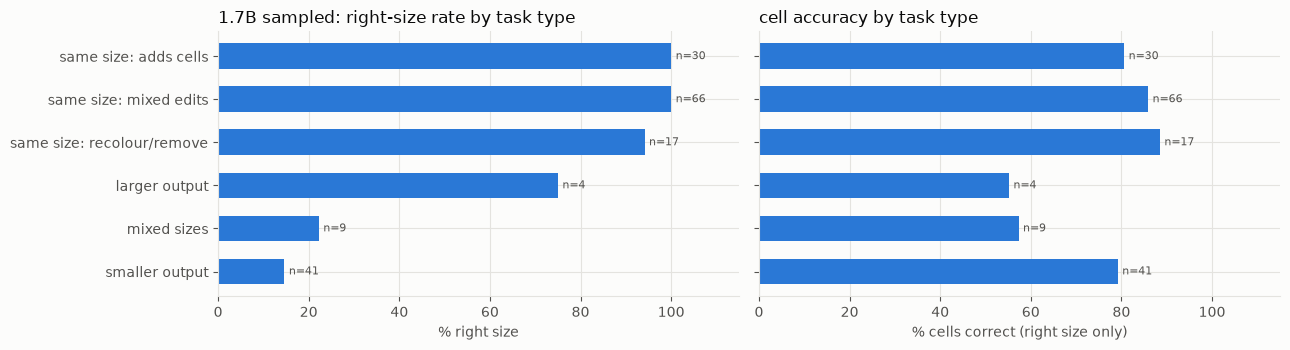

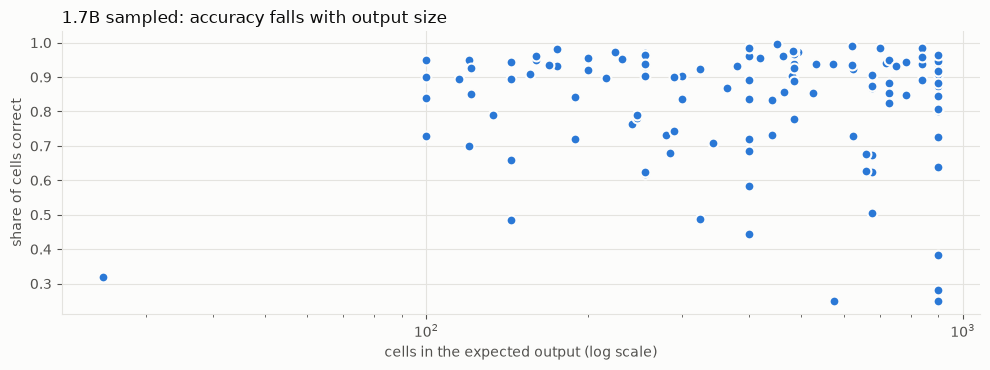

In [5]:
f = frames[last].copy()
by_cat = f.groupby("category").agg(tests=("task", "size"), right_size=("shape_ok", "mean"),
                                   cell_acc=("cell_acc", "mean"), solved=("correct", "sum"))
by_cat = by_cat.sort_values("right_size")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
axes[0].barh(by_cat.index, 100 * by_cat["right_size"], color=SERIES[0], height=0.6)
axes[0].set(xlabel="% right size", xlim=(0, 115), xticks=range(0, 101, 20))
axes[0].set_title(f"{last}: right-size rate by task type", loc="left")
axes[1].barh(by_cat.index, 100 * by_cat["cell_acc"].fillna(0), color=SERIES[0], height=0.6)
axes[1].set(xlabel="% cells correct (right size only)", xlim=(0, 115), xticks=range(0, 101, 20))
axes[1].set_title("cell accuracy by task type", loc="left")
for ax, col in zip(axes, ["right_size", "cell_acc"]):
    for i, (v, n) in enumerate(zip(by_cat[col].fillna(0), by_cat["tests"])):
        ax.text(100 * v + 1, i, f"n={n}", va="center", color=INK2, fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
ok = f[f["shape_ok"]]
ax.scatter(ok["out_cells"], ok["cell_acc"], s=50, color=SERIES[0], edgecolor="#fcfcfb", linewidth=1.5, zorder=2)
hit = ok[ok["correct"]]
ax.scatter(hit["out_cells"], hit["cell_acc"], s=90, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=3, label="solved")
ax.set(xscale="log", xlabel="cells in the expected output (log scale)", ylabel="share of cells correct")
ax.set_title(f"{last}: accuracy falls with output size", loc="left")
if len(hit):
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Does agreement between views predict correctness?

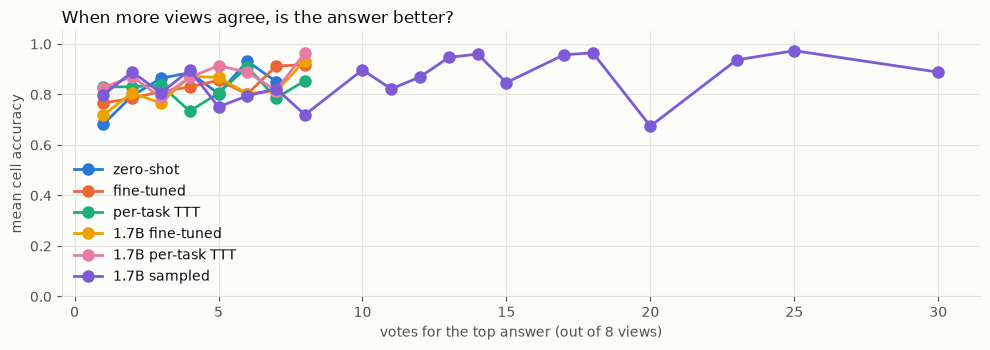

correct,False,All
top_votes,,
0,1,1
1,74,74
2,26,26
3,16,16
4,5,5
5,7,7
6,4,4
7,6,6
8,1,1


In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, f in frames.items():
    g = f[f["shape_ok"]].groupby("top_votes")["cell_acc"].mean()
    ax.plot(g.index, g.values, marker="o", markersize=8, color=COLOR[name], label=name)
ax.set(xlabel="votes for the top answer (out of 8 views)", ylabel="mean cell accuracy", ylim=(0, 1.05))
ax.set_title("When more views agree, is the answer better?", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
pd.crosstab(frames[last]["top_votes"], frames[last]["correct"], margins=True)

## 7. Examples

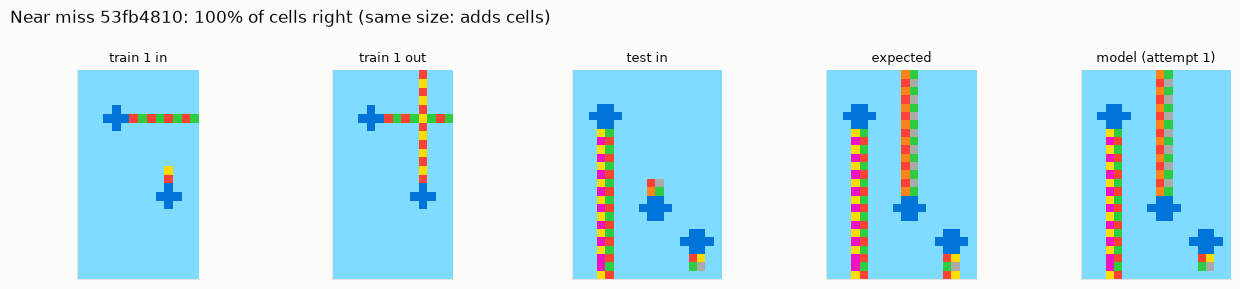

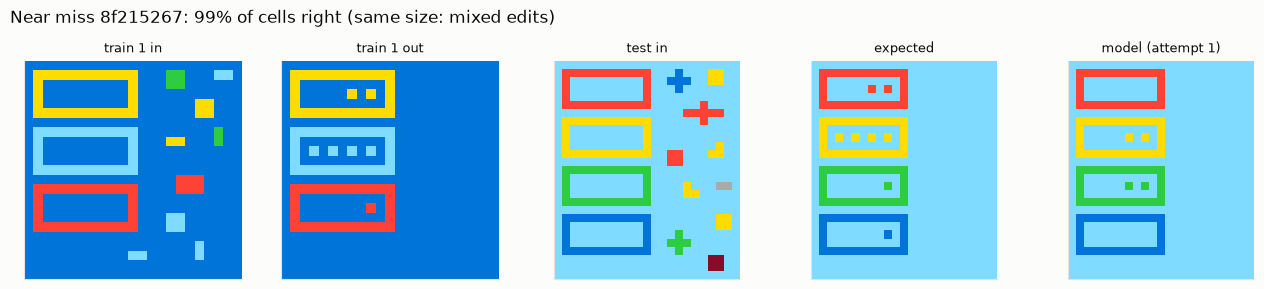

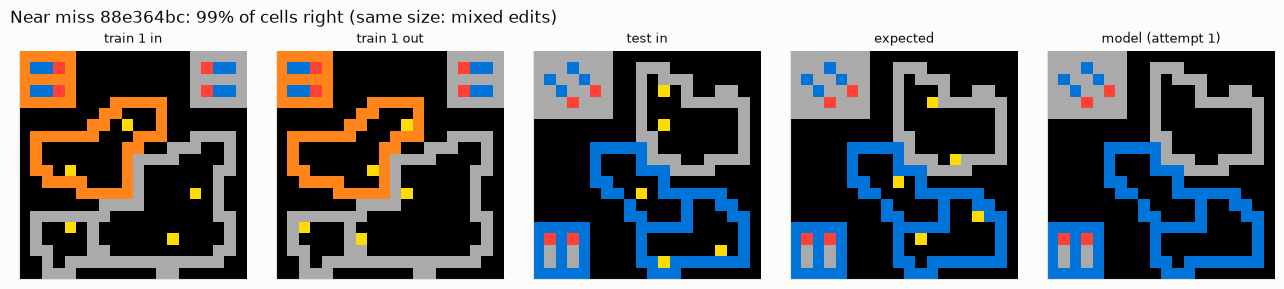

In [7]:
def show(task_id, test_idx, run_name, title):
    task = eval_tasks[task_id]
    tests = next(t for t in runs[run_name]["tasks"] if t["task"] == task_id)["tests"]
    pred = np.array(tests[test_idx]["attempts"][0]) if tests[test_idx]["attempts"] else None
    panels = [(task["train"][0][0], "train 1 in"), (task["train"][0][1], "train 1 out"),
              (task["test"][test_idx][0], "test in"), (task["test"][test_idx][1], "expected")]
    if pred is not None:
        panels.append((pred, "model (attempt 1)"))
    fig, axes = plt.subplots(1, len(panels), figsize=(2.6 * len(panels), 2.9))
    for ax, (g, label) in zip(axes, panels):
        ax.imshow(g, cmap=ARC_CMAP, vmin=0, vmax=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(label, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left")
    plt.tight_layout(); plt.show()


f = frames[last]
for _, r in f[f["correct"]].head(3).iterrows():
    show(r["task"], r["test"], last, f"Solved {r['task']} ({r['category']}), {r['top_votes']}/8 views agree")
near = f[f["shape_ok"] & ~f["correct"]].sort_values("cell_acc", ascending=False).head(3)
for _, r in near.iterrows():
    show(r["task"], r["test"], last, f"Near miss {r['task']}: {r['cell_acc']:.0%} of cells right ({r['category']})")

## 8. Choosing among candidates

The 1.7B sampled run was repeated with every candidate rescored (up to 40 per test input) and the
whole pool saved (`infer --pool`), so rankers can be compared offline. A summed log-probability
might favour small grids, since every extra cell adds a negative term; per-token scores and an
implied-shape filter test that.

166 test inputs, 4890 candidates; correct grid in the pool for 2: 2d0172a1, 8f215267


,score,rank of correct
ranker,,
oracle (correct anywhere in the pool),1.5,-
votes,0.0,"5, 15"
logprob sum (current),0.0,"4, 14"
logprob per token,0.0,"4, 14"
worst view per token,0.0,"6, 22"
"votes, then per token",0.0,"5, 15"
votes + implied shape,0.0,"5, 15"
logprob sum (current) + implied shape,0.0,"4, 14"
logprob per token + implied shape,0.0,"4, 14"


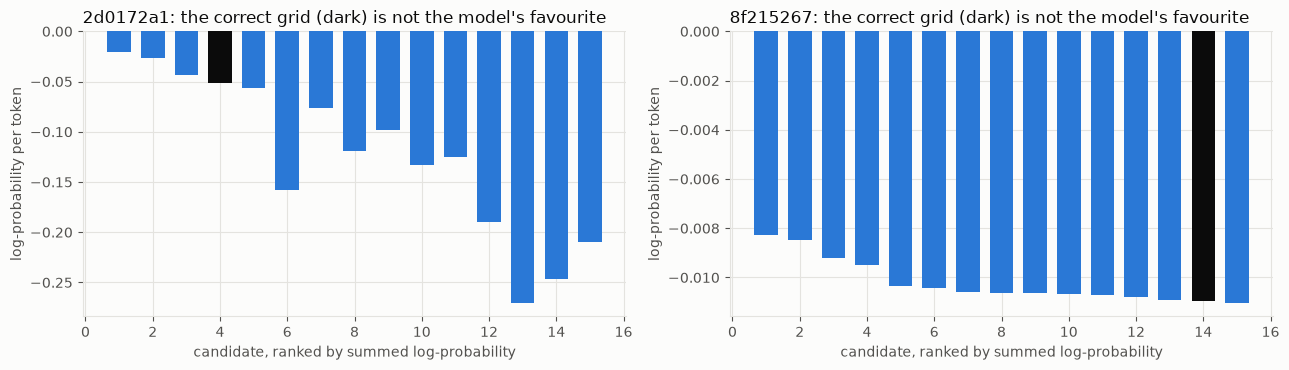

In [8]:
from llm.rank import RANKERS, rank, implied_shape, n_tokens

pool = json.loads((RES / "llm_pool_evaluation_ttt_task_pool_q17.json").read_text())
n_tests = pd.Series([r["task"] for r in pool]).value_counts()
in_pool = [r for r in pool if any(c["correct"] for c in r["candidates"])]
rows = [{"ranker": "oracle (correct anywhere in the pool)",
         "score": sum(1 / n_tests[r["task"]] for r in in_pool), "rank of correct": "-"}]
for use_shape in (False, True):
    for name, key in RANKERS.items():
        score, ranks = 0.0, []
        for r in pool:
            order = rank(r["candidates"], key, implied_shape(eval_tasks[r["task"]], r["test"]) if use_shape else None)
            score += any(c["correct"] for c in order[:2]) / n_tests[r["task"]]
            if r in in_pool:
                ranks.append(next(i for i, c in enumerate(order, 1) if c["correct"]))
        rows.append({"ranker": name + (" + implied shape" if use_shape else ""), "score": score,
                     "rank of correct": ", ".join(map(str, ranks))})
print(f"{len(pool)} test inputs, {sum(len(r['candidates']) for r in pool)} candidates; "
      f"correct grid in the pool for {len(in_pool)}: {', '.join(r['task'] for r in in_pool)}")
display(pd.DataFrame(rows).set_index("ranker"))

fig, axes = plt.subplots(1, len(in_pool), figsize=(6.5 * len(in_pool), 3.8), squeeze=False)
for ax, r in zip(axes[0], in_pool):
    cands = sorted(r["candidates"], key=lambda c: -sum(c["logprobs"]))[:15]
    per_tok = [np.mean(c["logprobs"]) / n_tokens(np.array(c["grid"]).shape) for c in cands]
    ax.bar(range(1, len(cands) + 1), per_tok, color=[INK if c["correct"] else SERIES[0] for c in cands], width=0.7)
    ax.set(xlabel="candidate, ranked by summed log-probability", ylabel="log-probability per token")
    ax.set_title(f"{r['task']}: the correct grid (dark) is not the model's favourite", loc="left")
plt.tight_layout(); plt.show()

## 9. Program synthesis with a 20B reasoning model

A different generator: `gpt-oss:20b` (run locally with Ollama) writes a Python `transform(grid)`,
which is kept only if it reproduces every demonstration exactly; a failed program goes back with
its first mismatch for revision (2 conversations x 3 rounds per task). The demonstrations act as
a check from outside the model, which the grid model's own likelihood could not provide (section 8).
Pilots on 20 random tasks per split (`llm/program.py`):

| Pilot | Reasoning | Notes |
|---|---|---|
| training, think medium | medium | 16k-token cap per call; a call that hits it yields no code |
| evaluation, think low | low | short reasoning |
| evaluation, think medium + forcing | medium | a call that hits the cap is handed back its reasoning and must write code (budget forcing) |

,tasks,solved,DSL on the same tasks,passed all demos,false positives,fallback solves,calls,no code %,forced,s / call,tokens / call
"training, think medium",20.0,10.0,2.0,11.0,1.0,1.0,78.0,56.4,0.0,140.3,13381.5
"evaluation, think low",20.0,0.0,0.0,0.0,0.0,0.0,120.0,38.3,0.0,5.9,481.3
"evaluation, think medium + forcing",20.0,0.0,0.0,1.0,1.0,0.0,119.0,2.5,57.0,117.0,11113.3


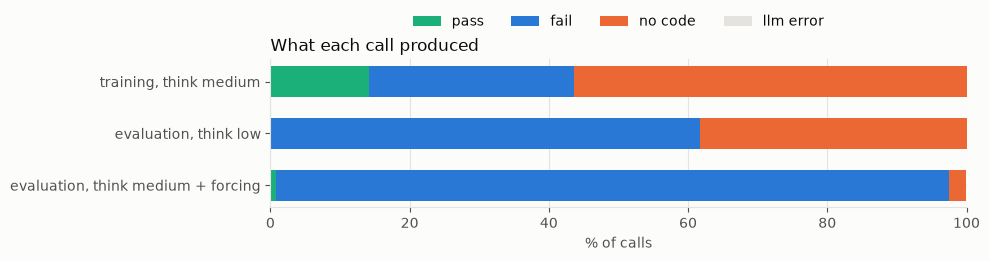

In [9]:
from llm.program import run_program

PROG = {"training, think medium": ("training", "prog_training_pilot_gptoss"),
        "evaluation, think low": ("evaluation", "prog_evaluation_pilot_gptoss_low"),
        "evaluation, think medium + forcing": ("evaluation", "prog_evaluation_pilot_gptoss_force")}
splits = {"training": load_split("training"), "evaluation": eval_tasks}
prog = {name: (split, [json.loads(l) for l in (RES / f"{f}.jsonl").open()])
        for name, (split, f) in PROG.items() if (RES / f"{f}.jsonl").exists()}
dsl_train = {r["task"]: r["score"] for r in json.loads((RES / "training_v2_uniform.json").read_text())["tasks"]}

summary = {}
for name, (split, rows) in prog.items():
    calls = [e for r in rows for e in r["log"] if "seconds" in e]
    summary[name] = {
        "tasks": len(rows), "solved": sum(r["score"] for r in rows),
        "DSL on the same tasks": sum(dsl_train.get(r["task"], 0) for r in rows) if split == "training" else 0,
        "passed all demos": sum(r["fit_train"] for r in rows),
        "false positives": sum(r["fit_train"] and r["score"] < 1 for r in rows),
        "fallback solves": sum(r.get("fallback_score", 0) for r in rows),
        "calls": len(calls), "no code %": 100 * np.mean([e["status"] == "no_code" for e in calls]),
        "forced": sum(e.get("forced", False) for e in calls),
        "s / call": np.mean([e["seconds"] for e in calls]), "tokens / call": np.mean([e["tokens_out"] for e in calls]),
    }
display(pd.DataFrame(summary).T.round(1))

fig, ax = plt.subplots(figsize=(10, 2.8))
outcomes = [("pass", SERIES[2]), ("fail", SERIES[0]), ("no_code", SERIES[1]), ("llm_error", GRID)]
for i, (name, (_, rows)) in enumerate(prog.items()):
    statuses = [e["status"] for r in rows for e in r["log"]]
    left = 0
    for status, color in outcomes:
        share = 100 * statuses.count(status) / len(statuses)
        ax.barh(i, share, left=left, color=color, height=0.6, label=status.replace("_", " ") if i == 0 else None)
        left += share
ax.set_yticks(range(len(prog)), list(prog)); ax.invert_yaxis(); ax.set_xlabel("% of calls")
ax.set_title("What each call produced", loc="left")
ax.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.12))
plt.tight_layout(); plt.show()

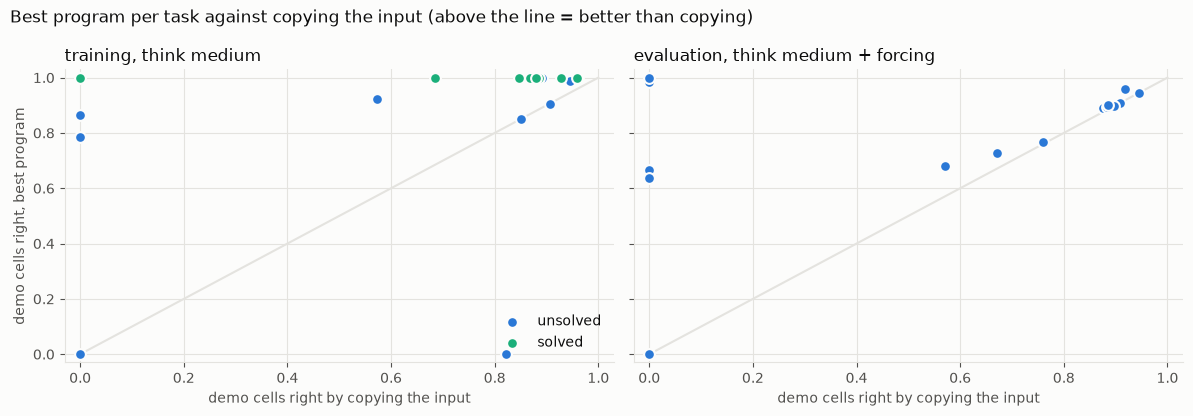

,unsolved,best_at_least_90pct,beats_copying,never_right_size
pilot,,,,
"training, think medium",10,5,6,2
"evaluation, think medium + forcing",20,5,12,6


In [10]:
def demo_accuracy(task, code):
    """Mean share of cells right over the demonstrations (0 for a wrong-size or failed output)."""
    outs = run_program(code, [x for x, _ in task["train"]])
    if isinstance(outs, str):
        return 0.0
    return float(np.mean([(o == y).mean() if not isinstance(o, str) and o.shape == y.shape else 0.0
                          for o, (_, y) in zip(outs, task["train"])]))


def copy_accuracy(task):
    return float(np.mean([(x == y).mean() if x.shape == y.shape else 0.0 for x, y in task["train"]]))


# Re-runs every saved program on its demonstrations (a minute or two)
closeness = []
for name, (split, rows) in prog.items():
    if "low" in name:
        continue
    for r in rows:
        task = splits[split][r["task"]]
        best = max([demo_accuracy(task, e["code"]) for e in r["log"] if "code" in e], default=0.0)
        closeness.append({"pilot": name, "task": r["task"], "best program": best, "copy input": copy_accuracy(task),
                          "solved": r["score"] > 0})
closeness = pd.DataFrame(closeness)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (name, g) in zip(axes, closeness.groupby("pilot", sort=False)):
    ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5, zorder=1)
    for solved, color, label in [(False, SERIES[0], "unsolved"), (True, SERIES[2], "solved")]:
        s = g[g["solved"] == solved]
        ax.scatter(s["copy input"], s["best program"], s=60, color=color, edgecolor="#fcfcfb", linewidth=1.5,
                   zorder=2, label=label)
    ax.set(xlabel="demo cells right by copying the input", xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
    ax.set_title(name, loc="left")
axes[0].set_ylabel("demo cells right, best program")
axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Best program per task against copying the input (above the line = better than copying)", x=0.01, ha="left")
plt.tight_layout(); plt.show()
unsolved = closeness[~closeness["solved"]]
display(unsolved.groupby("pilot", sort=False).agg(
    unsolved=("task", "size"), best_at_least_90pct=("best program", lambda s: int((s >= 0.9).sum())),
    beats_copying=("best program", lambda s: int((s > unsolved.loc[s.index, "copy input"]).sum())),
    never_right_size=("best program", lambda s: int((s == 0).sum()))))

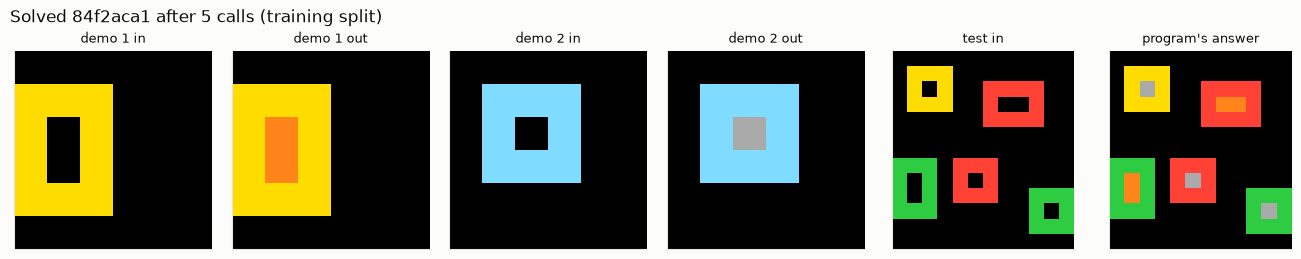

def transform(grid: list[list[int]]) -> list[list[int]]:
    """
    For each connected component of a non‑zero color, fill the zero cells inside its bounding rectangle:
        * if there is exactly one such cell → replace it with 5
        * otherwise (more than one)          → replace them with 7
    The original non‑zero cells remain unchanged.
    """
    H = len(grid)
    W = len(grid[0]) if H else 0
    res = [row[:] for row in grid]

    visited = [[False] * W for _ in range(H)]
    dirs = [(1, 0), (-1, 0), (0, 1), (0, -1)]

    for r in range(H):
        for c in range(W):
            if not visited[r][c] and grid[r][c] != 0:
                # BFS to collect component cells
                stack = [(r, c)]
                visited[r][c] = True
                comp_cells = set()
                min_r = max_r = r
                min_c = max_c = c

                while stack:
                    x, y = stack.pop()
                    comp_cells.add((x, y))
                    if 

In [11]:
def show_program(split, row, title):
    task = splits[split][row["task"]]
    passing = next(e for e in row["log"] if e["status"] == "pass")
    pairs = task["train"][:2] + [(task["test"][0][0], np.array(row["predictions"][0]))]
    fig, axes = plt.subplots(1, 2 * len(pairs), figsize=(2.2 * 2 * len(pairs), 2.6))
    labels = [f"demo {i + 1} {s}" for i in range(len(pairs) - 1) for s in ("in", "out")] + ["test in", "program's answer"]
    for ax, g, label in zip(axes, [g for p in pairs for g in p], labels):
        ax.imshow(g, cmap=ARC_CMAP, vmin=0, vmax=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(label, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left")
    plt.tight_layout(); plt.show()
    print(passing["code"])


split, rows = prog["training, think medium"]
solved = [r for r in rows if r["score"] > 0]
pick = max(solved, key=lambda r: len(r["log"]))  # the one that needed the most revisions
show_program(split, pick, f"Solved {pick['task']} after {len(pick['log'])} calls (training split)")

## 10. Findings

| | zero-shot | fine-tuned | + shared TTT | + per-task TTT | per-task, rescored | per-task v2 (rescored) | 1.7B fine-tuned (+RE-ARC) | 1.7B per-task (rescored) | 1.7B + sampling |
|---|---|---|---|---|---|---|---|---|---|
| Solved (of 120) | 0 | 0 | 0 | **0.5** | 0 | 0 | 0 | 0 | 0 |
| Valid grids | 57% | 77% | 84% | 80% | 80% | 84% | **89%** | **89%** | 88% |
| Right-size answers (of 167 test inputs) | 32% | 61% | 66% | 60% | 64% | 65% | 71% | **74%** | **74%** |
| Cell accuracy, same-size tests sized right (copying: 80.3%) | 80.8% | 82.2% | 80.9% | 83.9% | 84.6% | 84.3% | 80.6% | **85.0%** | 84.5% |
| Answers with >= 90% of cells right | â€“ | 39 | 43 | 36 | 48 | 47 | 46 | **62** | 61 |
| Answers with >= 99% of cells right | 0 | 0 | 0 | 2 | 2 | 1 | 0 | **3** | 2 |
| Training time | â€“ | 89 min | 44 min | 75 min | (same adapters) | 125 min | 244 min | 130 min | (same adapters) |
| Evaluation time (vLLM) | 10 min | 13 min | 12 min | 14 min | 27 min | 28 min | 15 min | 47 min | 103 min |

The shared TTT validation loss (0.144 â†’ 0.111) comes from rows of the same tasks it trained on, so it
is not a held-out number.

**1. Fine-tuning taught the format and the output size, not the rule.** The share of well-formed
grids rose from 57% to 77% and right-size answers nearly doubled (32% â†’ 61%). Most of the 64% drop
in validation loss is explained by this: getting dimensions, row lengths and the "copy most of the
grid" structure right is worth a lot of tokens.

**2. Until per-task training, the cell-level gain was almost entirely copying.** A trivial answer â€”
the test input, unchanged â€” already gets 80.3% of cells right on same-size tasks. The fine-tuned
model gets 82.2% on the same-size tests it sizes correctly (zero-shot: 80.8%).

**3. One shared test-time adapter helped the format again, but not the rules.** Training one adapter
on all 120 tasks' demonstration pairs (never their test outputs) raised valid grids to 84% and
right-size answers to 66%, and fixed the output size on some tasks (`8f215267`: wrong size â†’ 98.7%
of cells right). Its same-size cell accuracy, 80.9%, is level with copying.

**4. Per-task test-time training is the first step that learns something beyond copying.** A
separate adapter per task, trained only on that task's demonstrations, reaches 83.9% same-size cell
accuracy (3.6 points above copying) and produces the first exactly correct answer (`38007db0`,
test 2) plus a second answer with 4 of 621 cells wrong (`8f215267`). Each adapter sees a single rule,
so its steps are not spread across 120 different ones.

**5. The cost is format robustness and agreement.** With only 2â€“4 demonstrations per task, the
per-task adapters overfit: valid grids drop from 84% to 80%, right-size answers from 66% to 60%, and
the views agree less. The one solve won with a single vote (1 of 8 views; the two attempts tied at one
vote each), so it is fragile: the right answer was found, but voting barely kept it.

**6. Re-ranking by likelihood picks closer answers, not exact ones.** Scoring each test's top 8
candidates by their summed log-probability across all 8 views (instead of vote count) raises
right-size answers from 60% to 64% and answers with >= 90% of cells right from 36 to 48, but it ranks
two near misses above the correct grid on `38007db0`, losing the one solve. The model's likelihood
is a good guide to "close", not yet to "exactly right".

**7. More robust per-task training restored the format but not the solve.** With 24 augmentations
and 8 generic rows mixed into each task, valid grids return to 84% and right-size answers to 65%, and
cell accuracy holds at 84.3%. But nothing is solved by either ranking: the earlier solve was at the
edge of what this model finds, and a different random draw of augmentations loses it.

**8. Scale and more data improve everything except the solve count.** Qwen3-1.7B, fine-tuned on the
training split plus 10,000 RE-ARC pseudo-tasks (generated examples of the 400 original ARC training
tasks; none are evaluation tasks, and no generated pair matches an evaluation pair), writes valid
grids 89% of the time and right-size answers 71% of the time. On its own its cells are still at the
copying level (80.6%), like the 0.6B model before test-time training. With per-task adapters it is the
best run on every near-miss measure: 85.0% cell accuracy on same-size tests, 62 answers with at least
90% of cells right, and three within 1â€“2 cells (`53fb4810`: 2 of 450 wrong; `38007db0`: 1 of 175).
Still nothing is exactly right. The model and the data changed together, so this gain cannot be
credited to either alone. Its validation loss (0.375 â†’ 0.098) shares generators with the training
rows, so it is not a held-out number.

**9. The near misses are still copy tasks.** `e376de54`, `4c3d4a41` and `8e5c0c38` remain 3â€“17
cells away in every run; the remaining cells are exactly the ones the rule changes.

**10. Sampling finds a new answer but cannot rank it.** Adding 4 sampled answers per view
(temperature 0.7) to the 1.7B per-task run, 5,312 extra answers in all, and rescoring the top 12
candidates by likelihood puts the exactly correct grid among the candidates for 1 of 167 test
inputs (`2d0172a1`, a task no earlier run came close on). It was not ranked into the two attempts:
the top-ranked answer there is not even the right size. The other measures barely move (84.5% cell
accuracy, 61 answers with at least 90% of cells right), and `38007db0`'s 1-cell miss falls out of the
top two. Sampling adds some diversity, but likelihood ranking cannot tell the right answer from the near
misses. One found answer is too few to call ranking the main bottleneck, but it is the first place
where generation succeeded and selection failed.

**11. The ranking failure is not a length bias; the model prefers the wrong answers.** Finding 10
suggested a simple cause: a summed log-probability adds one negative term per cell, so smaller grids
score higher, and on `2d0172a1` the top answers (9x11, 9x9) were smaller than the correct 9x13. To
test it, the same run was repeated with every candidate rescored (up to 40 per test instead of the
top 12; 39,120 candidate views, 3.1 h) and the whole pool saved with per-view log-probabilities
(`infer --pool`, `results/llm_pool_evaluation_ttt_task_pool_q17.json`). Rankers were then compared
offline (`python -m llm.rank`). The pool held the correct grid for 2 of 167 test inputs (`2d0172a1`
again, and `8f215267`), so a perfect ranker would score 1.5/120. Every ranker tried scores 0:

| Ranker | Score | Rank of correct (`2d0172a1`, `8f215267`) |
|---|---|---|
| votes | 0 | 5, 15 |
| summed log-prob (the run's own) | 0 | 4, 14 |
| log-prob per token | 0 | 4, 14 |
| worst view, per token | 0 | 6, 22 |
| any of the above, implied-shape candidates first | 0 | same |
| oracle (correct anywhere in the pool) | 1.5 | â€“ |

Normalising by size changes nothing: on `2d0172a1` the correct grid is also the least likely per
token of the top four (-0.052 against -0.021 for the 9x11 answer), and its output size is not
fixed by the demonstrations (11x12, 5x5, 7x5, 9x11), so no shape filter applies. On `8f215267` all
32 candidates are the right size and the top 13 are 2â€“8 cells from the answer; the correct grid
trails the best by 14 nats summed over 8 views, under 2 per view. So the model is not mis-scored
by a fixable artefact: its per-task adapter genuinely finds the near misses more likely, and among
candidates a few cells apart its likelihood carries almost no signal. Better ranking alone would
reach at most 1.5/120 here; generation, which got the right answer into the pool for 2 of 167
inputs, is the larger bottleneck.

**12. A 20B model writing programs solves half the training tasks but no evaluation tasks.** A
different generator: `gpt-oss:20b`, run locally with Ollama, writes a Python `transform(grid)`; the
program is kept only if it reproduces every demonstration exactly, and a failed one goes back with
its first mismatch for revision (2 conversations x 3 rounds per task; `llm/program.py`). Running
the code on the demonstrations is the check from outside the model that finding 11 found missing.
Pilots on 20 random tasks per split (section 9):

| Pilot | Solved | DSL, same tasks | Passed all demos | Calls without code | Time per call |
|---|---|---|---|---|---|
| training, think medium | **10/20** | 2/20 | 11 (1 wrong on test) | 56% | 140 s |
| evaluation, think low | 0/20 | 0 | 0 | 38% | 6 s |
| evaluation, think medium + forcing | 0/20 | 0 | 1 (wrong on test) | 2.5% | 117 s |

On training tasks it is the strongest solver in the project: 5x the DSL on the same tasks, solving
both of the DSL's tasks, four of them only after feedback rounds, and it reached that score while
over half its calls produced nothing (medium reasoning ran past the 16k-token cap). On evaluation
it solves nothing. With low reasoning the model gives up within ~500 tokens (on `dfadab01`: "Hard.
Given limited time, maybe identity?") and returns the input unchanged. With medium reasoning plus
budget forcing (a call that hits the cap is handed back the tail of its reasoning and must write
code), almost every call produces a program, but no program reproduces even one demonstration of
19 of the 20 tasks. The best program for 12 of 20 tasks beats copying the input, mostly by a few
points: the programs get the easy cells and miss the rule. The one program that passed (`45a5af55`)
fitted only 2 demonstrations and returned a 23x23 grid for a 26x26 answer, showing how few
demonstrations limit this check.

Two infrastructure bugs cost runs and are worth recording: under the runner's memory cap, `import
numpy` hung on the 112-core server (OpenBLAS reserves memory per core) until the timeout, silently
failing every program that used numpy; and the Ollama container was stopped mid-run, which now
triggers retries instead of empty results.

### What this suggests next
Every step has moved the answers closer, but none has crossed into exact answers: ARC scores only
grids with every cell right, and the last 1â€“10 cells are exactly the ones the rule changes.
- **Program synthesis is the approach to scale:** checking candidates against the demonstrations
  works (11 passes on training, 1 wrong), but the generator has to find the rule first. That
  needs a stronger reasoning model than a local 20B one, or many more samples per task with
  parallel requests; the training pilot should also be rerun with budget forcing for a fair number.
- **Ranking needs a signal other than the model's own likelihood:** size normalisation and shape
  filters were tried and do not help (finding 11). Even a perfect ranker reaches only 1.5/120
  here, so this is worth doing only alongside better generation.
- **Larger models and far more data:** published LLM approaches use 4â€“8B models trained on
  hundreds of thousands of RE-ARC-style examples, against 1.7B and 20k here.
- **Combine with the DSL:** the DSL is exact when one of its programs fits; the LLM's strength so far
  is producing a well-sized, near-correct canvas.